MUHAMMAD YUSUF 2411512010 PEMOGRAMAN PARALEL B

1. ANALISIS SPEEDUP SKALA

Mulai mengeksekusi komputasi multiprocessing, mohon tunggu...
Jumlah Worker 1 selesai dalam -> 7.65 detik
Jumlah Worker 2 selesai dalam -> 3.94 detik
Jumlah Worker 4 selesai dalam -> 2.32 detik
Jumlah Worker 8 selesai dalam -> 1.55 detik


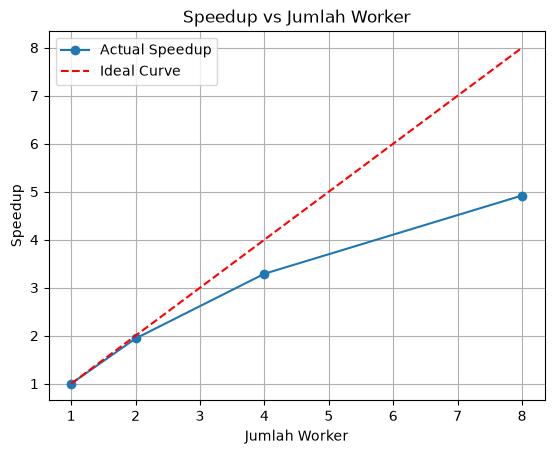

In [3]:
import os
import time
import multiprocessing as mp
import matplotlib.pyplot as plt

kode_fungsi = """def hitung_prima(n):
    primes = []
    for num in range(2, n):
        is_prime = True
        for i in range(2, int(num**0.5) + 1):
            if num % i == 0:
                is_prime = False
                break
        if is_prime: 
            primes.append(num)
    return len(primes)
"""

with open("worker_prima.py", "w") as file:
    file.write(kode_fungsi)

from worker_prima import hitung_prima


if __name__ == '__main__':
    print("Mulai mengeksekusi komputasi multiprocessing, mohon tunggu...")
    

    tugas = [500000] * 8 
    workers_list = [1, 2, 4, 8]
    waktu_eksekusi = []

   
    ctx = mp.get_context('spawn')

    for w in workers_list:
        start_time = time.time()
        
        
        with ctx.Pool(processes=w) as pool:
            pool.map(hitung_prima, tugas)
            
        waktu = time.time() - start_time
        waktu_eksekusi.append(waktu)
        print(f"Jumlah Worker {w} selesai dalam -> {waktu:.2f} detik")

    
    t1 = waktu_eksekusi[0]
    speedup = [t1 / t for t in waktu_eksekusi]

    
    plt.plot(workers_list, speedup, marker='o', label='Actual Speedup')
    plt.plot(workers_list, workers_list, linestyle='--', color='red', label='Ideal Curve')
    plt.title("Speedup vs Jumlah Worker")
    plt.xlabel("Jumlah Worker")
    plt.ylabel("Speedup")
    plt.legend()
    plt.grid(True)
    plt.show()

Berdasarkan grafik di atas, kurva aktual tidak persis mengikuti kurva ideal teoritis (Hukum Amdahl). Terdapat beberapa alasan teknis mengapa hal ini terjadi. Overhead Pembuatan Proses, Terdapat beban waktu ekstra (overhead) yang dibutuhkan oleh sistem operasi (Windows) untuk melakukan spawning (membuka proses Python baru secara berulang) dan mengalokasikan memori setiap kali worker ditambahkan. Keterbatasan Core Fisik, Performa dibatasi oleh jumlah core fisik pada prosesor. Ketika jumlah worker dipaksa berjalan mendekati atau melebihi kapasitas total core fisik, sistem akan sibuk melakukan antrean dan pergantian giliran sehingga mengurangi kecepatan.   

Penjelasan Kode :

import os, time, multiprocessing as mp, matplotlib.pyplot as plt: Mengimpor modul yang dibutuhkan

def hitung_prima(n): hingga return len(primes): Ini adalah kode di dalam teks tadi. Logikanya adalah melakukan perulangan matematika standar untuk mencari jumlah bilangan prima dari angka 2 hingga ke n.

file.write(kode_fungsi): Menuliskan seluruh isi string teks tadi ke dalam file yang baru saja dibuat.

from worker_prima import hitung_prima: Mengimpor fungsi hitung_prima dari file worker_prima.py yang baru dibuat

if __name__ == '__main__'::  Perintah ini memastikan bahwa kode di bawahnya hanya akan dieksekusi satu kali oleh proses utama (Main Process), dan tidak dieksekusi berulang kali saat OS melakukan spawning (penggandaan proses di latar belakang).

print(...): Menampilkan teks untuk memberi tahu pengguna bahwa program sudah mulai berjalan.

tugas = [500000] * 8: Membuat daftar/list berisi 8 elemen dengan nilai masing-masing 50.000.

workers_list = [1, 2, 4, 8]: Menentukan skenario pengujian jumlah worker (prosesor) yang digunakan secara paralel.

waktu_eksekusi = []: Tempat menampung data durasi waktu dari tiap-tiap penyelesaian tugas.

ctx = mp.get_context('spawn'): Memberi tahu Python untuk secara tegas menggunakan mode spawn dalam membuat proses baru.

for w in workers_list:: Memulai perulangan untuk menguji mulai dari 1 worker, lalu 2, 4, hingga 8 worker.

start_time = time.time(): Mencatat waktu saat ini (sebelum komputasi dimulai) sebagai titik mulai.

with ctx.Pool(processes=w) as pool:: Membuka kolam (pool) proses dengan jumlah pekerja dibatasi maksimal w orang. Otomatis menutup pool jika sudah selesai.

pool.map(hitung_prima, tugas): Membagikan 8 paket tugas tersebut ke dalam kolam proses. Metode map akan secara otomatis membagi beban tugas seadil mungkin ke jumlah pekerja yang aktif saat itu. Program akan terkunci (menunggu) di baris ini sampai semua proses berhasil dikerjakan.

waktu = time.time() - start_time: Menghitung total durasi dengan cara: Waktu Selesai (saat ini) dikurangi Waktu Mulai (start_time).

waktu_eksekusi.append(waktu): Menyimpan durasi waktu pengujian skenario ini ke dalam list.

print(...): Mencetak laporan durasi ke layar untuk 1 skenario pengujian.

t1 = waktu_eksekusi[0]: Mengambil nilai durasi waktu di posisi indeks 0 (waktu saat dikerjakan oleh 1 worker) sebagai acuan kecepatan.

speedup = [t1 / t for t in waktu_eksekusi]: Menghitung percepatan menggunakan list comprehension.

plt.plot(workers_list, speedup, marker='o', label='Actual Speedup'): Menggambar garis utama yang mewakili performa speedup aktual hasil dari tes komputer. marker='o' memberi tanda titik bulat pada tiap pertemuan nilai.

plt.plot(workers_list, workers_list, linestyle='--', color='red', label='Ideal Curve'): Menggambar garis panduan lurus putus-putus berwarna merah (Hukum Amdahl). Secara teoretis, jika mesin 100% sempurna, memakai 4 worker harusnya 4 kali lebih cepat, 8 worker 8 kali lebih cepat, dan seterusnya.

Baris plt.title hingga plt.show(): menampilkan judul grafik, memberikan label "Jumlah Worker" di garis bawah (sumbu X) dan "Speedup" di garis kiri (sumbu Y), menampilkan kotak legenda penjelas garis, menyalakan pola kotak-kotak (grid).

2. SHARED MEMORY VS MESSAGE PASSING

In [2]:
import time
import multiprocessing as mp

kode_fungsi = """import random

def worker_queue(q):
    subtotal = sum(random.random() for _ in range(1000000))
    q.put(subtotal)

def worker_value(shared_val, lock):
    subtotal = sum(random.random() for _ in range(1000000))
    with lock:
        shared_val.value += subtotal
"""

with open("worker_ipc.py", "w") as file:
    file.write(kode_fungsi)

from worker_ipc import worker_queue, worker_value

if __name__ == '__main__':
    print("Mengeksekusi komputasi, mohon tunggu...")
    
    ctx = mp.get_context('spawn')

    start_q = time.time()
    q = ctx.Queue()
    
    processes_q = [ctx.Process(target=worker_queue, args=(q,)) for _ in range(4)]
    for p in processes_q: 
        p.start()
        
    total_q = sum(q.get() for _ in range(4))
    
    for p in processes_q: 
        p.join()
        
    print(f"Queue Total: {total_q} | Waktu: {time.time() - start_q:.4f} dtk")

    start_v = time.time()
    
    shared_val = ctx.Value('d', 0.0)
    lock = ctx.Lock()
    
    processes_v = [ctx.Process(target=worker_value, args=(shared_val, lock)) for _ in range(4)]
    for p in processes_v: 
        p.start()
        
    for p in processes_v: 
        p.join()
        
    print(f"Value Total: {shared_val.value} | Waktu: {time.time() - start_v:.4f} dtk")

Mengeksekusi komputasi, mohon tunggu...
Queue Total: 2000322.286919919 | Waktu: 0.1826 dtk
Value Total: 2000816.8196456926 | Waktu: 0.1845 dtk


Metode Queue (Message Passing) mencatat waktu eksekusi 0,1826 detik, sedangkan metode Value (Shared Memory) mencatat waktu 0,1845 detik. Selisih waktu keduanya sangat kecil dan tidak signifikan (hanya 0,0019 detik), menunjukkan bahwa kedua arsitektur mampu menangani beban komputasi CPU dengan sama baiknya di mesin. Kehadiran Overhead pada Gembok (Lock) Secara arsitektur perangkat keras, memori bersama (Shared Memory) seharusnya memiliki kecepatan transfer yang lebih superior karena diakses langsung di RAM. Namun, hasil eksekusi menunjukkan Value sedikit lebih lambat dibandingkan Queue. Hal ini membuktikan adanya overhead dari penggunaan Lock() secara terus-menerus. 

Penjelasan Kode :

from worker_ipc import worker_queue, worker_value: Mengimpor kedua fungsi tadi dari file fisik agar terhindar dari bug sistem spawning pada Jupyter.

if __name__ == '__main__':: Perlindungan wajib yang sama, mencegah proses latar belakang ikut-ikutan mencetak output atau menjalankan proses berulang.

ctx = mp.get_context('spawn'): Mengatur mesin multiprocessing agar selalu menggunakan mode spawn.

start_q = time.time(): Mencatat waktu dimulainya versi (a).   

q = ctx.Queue(): Membuat pipa antrean komunikasi antar-proses.   

processes_q = [...]: Membuat daftar berisi 4 proses, masing-masing diberikan tugas worker_queue dan dibekali pipa antrean q.   

for p in processes_q: p.start(): Menyalakan keempat prosesor secara serentak.   

total_q = sum(q.get() for _ in range(4)): Proses utama menunggu di depan pipa, menyedot 4 buah hasil yang datang satu per satu dari prosesor pekerja, lalu menjumlahkannya semua.   

for p in processes_q: p.join(): Memastikan keempat pekerja ini sudah benar-benar mati/berhenti beroperasi sebelum pindah ke tahap selanjutnya.   

print(...): Menampilkan hasil dan waktu eksekusinya.

start_v = time.time(): Mencatat waktu dimulainya versi (b).   

shared_val = ctx.Value('d', 0.0): Membuat satu petak RAM memori berjenis desimal 

lock = ctx.Lock(): Membuat sistem gembok (kunci) agar keempat pekerja tidak bertabrakan (race condition) saat mencoba menambahkan angka ke memori tersebut secara bersamaan.   

processes_v = [...]: Membuat daftar 4 pekerja, namun kali ini dibekali peta menuju shared_val dan kunci lock.   

for p in processes_v: p.start() & for p in processes_v: p.join(): Menyalakan pekerja, menunggunya mengubah variabel langsung di memori, dan memastikannya mati setelah selesai bekerja.

print(..., shared_val.value): Menampilkan total yang diambil langsung dari memori yang sudah diubah (via properti .value) beserta lama waktu pengerjaannya.

3. PRODUCER-CONSUMER ANTAR PROSES

In [5]:
import multiprocessing as mp

#Menulis fungsi ke file fisik untuk menghindari silent crash di Windows
kode_fungsi = """def hitung_faktorial(n):
    res = 1
    for i in range(1, n+1): res *= i
    return len(str(res))

def producer_mp(q):
    for i in range(5):
        tugas = 20000 + (i * 1000)
        q.put(tugas)
        print(f"[Producer] Generate task f({tugas})")
    q.put(None) 

def consumer_mp(q):
    while True:
        tugas = q.get()
        if tugas is None:
            break
        print(f"[Consumer] Memproses f({tugas})...")
        hasil = hitung_faktorial(tugas)
        print(f"[Consumer] Selesai. Hasil: {hasil} digit.")
"""

with open("worker_prodcons.py", "w") as file:
    file.write(kode_fungsi)

from worker_prodcons import producer_mp, consumer_mp


if __name__ == '__main__':
    print("Memulai Producer-Consumer antar-proses...")
    
    
    ctx = mp.get_context('spawn')
    
    q = ctx.Queue()
    p_prod = ctx.Process(target=producer_mp, args=(q,))
    p_cons = ctx.Process(target=consumer_mp, args=(q,))

    p_prod.start()
    p_cons.start()

    p_prod.join()
    p_cons.join()
    
    print("Selesai!")

Memulai Producer-Consumer antar-proses...
Selesai!


Pola kode secara struktur hampir tidak berubah sama sekali. Arsitektur logika program, seperti cara producer menaruh data ke dalam antrean (q.put()) dan cara consumer mengambilnya (q.get()), tetap sama persis. Perbedaan mutlaknya hanyalah pada penggantian namespace modul yang digunakan, yaitu dari threading.Thread menjadi multiprocessing.Process, dan queue.Queue menjadi multiprocessing.Queue. Terdapat lonjakan performa yang sangat signifikan. Jika tugas komputasi berat (CPU-bound) dipaksakan menggunakan threading, performanya akan lambat dan tertahan oleh Global Interpreter Lock (GIL) milik Python yang hanya mengizinkan satu thread beroperasi pada satu waktu. Dengan menggunakan multiprocessing pada tugas CPU-bound, batasan GIL berhasil dilewati karena program memecah dirinya menjadi beberapa proses mandiri di sistem operasi, sehingga perhitungan faktorial yang berat bisa didistribusikan dan dieksekusi secara nyata (paralel murni) ke berbagai core fisik prosesor.  

import multiprocessing as mp: Mengimpor modul bawaan Python untuk menjalankan dan mengelola beberapa proses secara bersamaan.

kode_fungsi = """ ... """: Variabel teks ini menyimpan seluruh kode dari tiga fungsi utama kita. 

def hitung_faktorial(n)::  Fungsi untuk menghitung faktorial sebuah angka 

return len(str(res)): (Di dalam teks) Daripada mengembalikan angka hasil yang panjangnya bisa jutaan karakter dan membuat Jupyter lag, baris ini hanya mengembalikan jumlah digit/panjang dari hasil faktorial tersebut.

def producer_mp(q):: (Di dalam teks) Fungsi Produsen. Ia melakukan perulangan 5 kali untuk menciptakan angka tugas (20000, 21000, dst), lalu menaruhnya ke dalam pipa antrean dengan perintah q.put(tugas). Di akhir perulangan, ia menaruh sinyal None sebagai tanda "tugas habis".

def consumer_mp(q):: (Di dalam teks) Fungsi Konsumen. Ia melakukan looping tanpa henti (while True) untuk mengambil tugas dari antrean (q.get()). Jika yang diambil adalah None, ia akan menghentikan looping (break). Jika angka, ia memproses faktorialnya.

with open("worker_prodcons.py", "w") as file: & file.write(kode_fungsi): Python membuka/membuat file fisik bernama worker_prodcons.py di laptop Anda, lalu menuliskan seluruh fungsi yang ada di dalam teks tadi ke dalamnya.

from worker_prodcons import producer_mp, consumer_mp: Memanggil fungsi dari file fisik yang baru saja dicetak. Ini memastikan proses-proses bayangan di latar belakang Windows tidak crash karena mereka kini tahu di mana harus mencari fungsi tersebut.

if __name__ == '__main__'::  Baris ini menjamin kode di bawahnya tidak tereksekusi dua kali saat Windows menggandakan (spawning) proses ke memori.

ctx = mp.get_context('spawn'): Memaksa Python menggunakan mode spawn dalam menciptakan proses baru. Ini adalah mode paling aman dan baku untuk sistem operasi Windows.

q = ctx.Queue(): Menciptakan sebuah pipa antrean (Queue) yang aman digunakan lintas proses (inter-process communication). Pipa ini adalah jembatan antara memori Produsen dan Konsumen.

p_prod = ctx.Process(target=producer_mp, args=(q,)): Menugaskan proses baru di OS Anda sebagai Produsen, diberikan akses ke pipa q.

p_cons = ctx.Process(target=consumer_mp, args=(q,)): Menugaskan proses baru lainnya di OS Anda sebagai Konsumen, juga diberikan akses ke pipa q.

p_prod.start() & p_cons.start(): Tombol daya ditekan. Sistem operasi meluncurkan kedua proses tersebut secara paralel dan nyata di latar belakang.

p_prod.join() & p_cons.join(): Memerintahkan proses utama (Jupyter) untuk menunggu dan tidak menutup skrip sampai tugas Produsen dan Konsumen benar-benar tuntas.

4. REFLEKSI SINGKAT

Memilih Manager(): Jika sebuah program memerlukan struktur data Python yang lebih tinggi dan kompleks antar-proses (seperti Dictionary atau List dinamis untuk menyimpan log aktivitas). Trade-off: Penulisan kodenya jauh lebih mudah dan intuitif, tetapi menanggung performa yang lambat akibat overhead di baliknya.   

Memilih Value / Array: Jika fokus pada performa masif saat berbagi perhitungan bertipe primitif (hanya integer, float atau array ukuram tetap). Trade-off: Secara teknis sangat cepat karena terhubung pada shared memori level bawah RAM, namun sintaks penulisannya sulit dan rentan race condition jika penggunaan Lock tidak berhati-hati.   